# VRP (Arc-Based Formulation) → QUBO (Penalty Formulation)

This notebook presents a **simplified Vehicle Routing Problem (VRP)** formulation and shows how to convert it into a **QUBO model** using penalty terms.

## Problem setting

- We have a **depot (node 0)**.
- We have **customers (nodes 1..n)**.
- We have **K identical vehicles**.
- Each vehicle starts and ends at the depot.
- Each customer must be visited **exactly once**.
- The objective is to **minimize total travel distance**.

## Modeling idea (Arc-Based)

We use binary decision variables:

$$
x_{ij} =
\begin{cases}
1 & \text{if a vehicle travels from node } i \text{ to node } j \\
0 & \text{otherwise}
\end{cases}
$$

This formulation requires:

$$
O(n^2)
$$

In [4]:
# Imports
import numpy as np
import sympy as sp
import matplotlib.pyplot as plt
import networkx as nx
import json

np.set_printoptions(linewidth=120, suppress=True)

## 1) Create Instance

In the VRP without capacity we only need:

- Travel costs $ c_{ij} $

### Define Number of Vehicles

In [5]:
K = 1             # number of vehicles

### Random Instance Generator


We generate a symmetric cost matrix using random 2D coordinates and Euclidean distance.

In [6]:
import numpy as np

def generate_instance(n_customers, seed=0):
    rng = np.random.default_rng(seed)

    n = n_customers + 1

    # -------------------------
    # 1) Coordenadas
    # -------------------------
    coords = rng.uniform(0, 10, size=(n, 2))

    # distância euclidiana
    dist = np.linalg.norm(coords[:, None, :] - coords[None, :, :], axis=-1)
    distance = np.rint(dist * 10).astype(int)

    # -------------------------
    # 2) Congestionamento
    # -------------------------
    congestion = rng.uniform(0.8, 2.5, size=(n, n))

    # simetrizar
    congestion = (congestion + congestion.T) / 2

    # tempo correlacionado com distância
    time = dist * congestion**2
    time = np.rint(time * 100).astype(int)

    # -------------------------
    # 3) Risco (independente)
    # -------------------------
    risk = rng.integers(1, 10, size=(n, n))
    risk = (risk + risk.T) // 2

    # -------------------------
    # 4) Custo/pedágio (independente)
    # -------------------------
    cost = rng.integers(5, 50, size=(n, n))
    cost = (cost + cost.T) // 2

    # -------------------------
    # remover diagonais
    # -------------------------
    for M in [distance, time, risk, cost]:
        np.fill_diagonal(M, 0)

    return distance, time, risk, cost, coords


# -------------------------
# Example
# -------------------------
n_customers = 4
seed = 0

dist_matrix, time_matrix, risk_matrix, cost_matrix, coords = generate_instance(n_customers, seed)

print("Distance matrix")
print(dist_matrix)

print("\nTime matrix")
print(time_matrix)

print("\nRisk matrix")
print(risk_matrix)

print("\nCost matrix")
print(cost_matrix)

# c_core = dist_matrix
# c_core = time_matrix
# c_core = risk_matrix
# c_core = cost_matrix

Distance matrix
[[  0  65  67  46  67]
 [ 65   0 118  91 105]
 [ 67 118   0  28  27]
 [ 46  91  28   0  22]
 [ 67 105  27  22   0]]

Time matrix
[[   0  586 1608  614 2702]
 [ 586    0 2207 3294 2324]
 [1608 2207    0 1317  559]
 [ 614 3294 1317    0  831]
 [2702 2324  559  831    0]]

Risk matrix
[[0 6 5 5 5]
 [6 0 7 5 6]
 [5 7 0 3 5]
 [5 5 3 0 3]
 [5 6 5 3 0]]

Cost matrix
[[ 0 15 26 25 41]
 [15  0 13 13 38]
 [26 13  0 39 17]
 [25 13 39  0 42]
 [41 38 17 42  0]]


### Visualize Graph

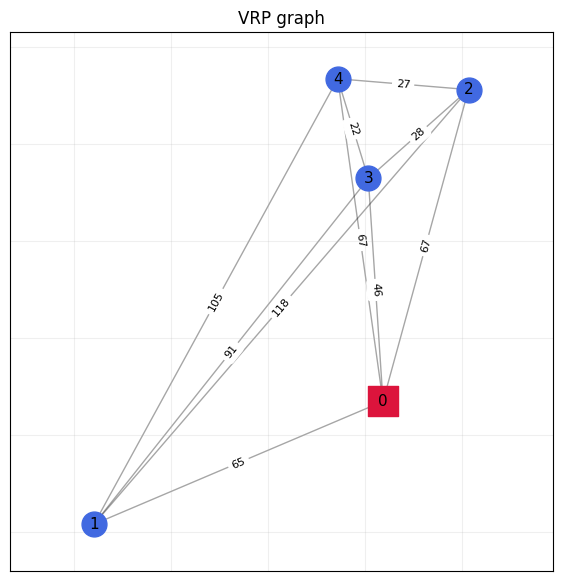

In [7]:
def draw_vrp_graph_networkx(coords, c_core, title="VRP graph",
                            cost_threshold=None,
                            show_weights=True, figsize=(7,7)):
    coords = np.asarray(coords)
    c = np.asarray(c_core)
    n_nodes = coords.shape[0]

    G = nx.Graph()
    for i in range(n_nodes):
        G.add_node(i, pos=(coords[i,0], coords[i,1]))

    # Add edges (complete graph unless threshold applied)
    for i in range(n_nodes):
        for j in range(i+1, n_nodes):
            if cost_threshold is None or c[i,j] <= cost_threshold:
                G.add_edge(i, j, weight=int(c[i,j]))

    pos = {i: (coords[i,0], coords[i,1]) for i in range(n_nodes)}
    plt.figure(figsize=figsize)

    # Depot in red square, customers in blue circles
    nx.draw_networkx_nodes(G, pos, nodelist=[0],
                           node_color="crimson", node_shape="s", node_size=450)
    nx.draw_networkx_nodes(G, pos,
                           nodelist=list(range(1, n_nodes)),
                           node_color="royalblue", node_shape="o", node_size=320)

    nx.draw_networkx_edges(G, pos, alpha=0.35, width=1.0)
    nx.draw_networkx_labels(G, pos, font_size=11, font_color="black")

    if show_weights:
        edge_labels = {(u,v): d["weight"] for u,v,d in G.edges(data=True)}
        nx.draw_networkx_edge_labels(G, pos, edge_labels=edge_labels, font_size=8)

    plt.title(title)
    plt.axis("equal")
    plt.grid(True, alpha=0.2)
    plt.show()


draw_vrp_graph_networkx(coords, c_core)

## 2) Sets and notation


- Depot: node **0**
- Customers: $ C = \{1,\dots,n\} $
- Full node set:  
  $$
  V = \{0\} \cup C
  $$

### Binary variable

$$
x_{ij} = 1 \iff \text{a vehicle travels from node } i \text{ to node } j
$$

for all $ i,j \in V $, with $ i \ne j $.

### Interpretation

- If $ x_{ij} = 1 $, some vehicle uses arc $ i \to j $.
- The number of vehicles is controlled by the number of arcs leaving and entering the depot.

In [8]:
def build_sets(n_customers):
    depot = 0
    customers = list(range(1, n_customers + 1))
    V = [depot] + customers
    return depot, customers, V


depot, C, V = build_sets(n_customers)

print("Depot:", depot)
print("Customers:", C)
print("Node set V:", V)
print("Number of possible directed arcs (excluding self-loops):",
      len(V) * (len(V) - 1))

Depot: 0
Customers: [1, 2, 3, 4]
Node set V: [0, 1, 2, 3, 4]
Number of possible directed arcs (excluding self-loops): 20


## 3) Variable indexing: map $ x_{ij} $ into a single QUBO vector


A QUBO uses one large binary vector $ z $.

We map each decision variable $ x_{ij} $ (arc selection) to a unique index in that vector.

### Decision variables

$$
x_{ij} =
\begin{cases}
1 & \text{if a vehicle travels from node } i \text{ to node } j \\
0 & \text{otherwise}
\end{cases}
$$

for all $ i, j \in V $, with $ i \ne j $.

The total number of binary variables is simply:

$$
|V| (|V| - 1)
$$

which scales as $ O(n^2) $.

In [9]:
def variable_indexing(V):
    """
    Map each arc variable x_{ij}, i != j, to a unique QUBO index.
    """
    x_index = {}
    idx = 0

    for i in V:
        for j in V:
            if i != j:
                x_index[(i, j)] = idx
                idx += 1

    return x_index, idx


x_index, n_vars = variable_indexing(V)

print("Total binary variables:", n_vars)
print("Expected |V|*(|V|-1) =", len(V) * (len(V) - 1))

Total binary variables: 20
Expected |V|*(|V|-1) = 20


## 4) QUBO construction helpers


We construct an energy:
$$
H(z) = z^T Q z + \text{constant}
$$

We use helper functions to add:
- linear terms $a z_i$ (store as diagonal)
- quadratic terms $b z_i z_j$ (store in upper triangle)
- squared penalties of affine expressions $(\sum a_i z_i + c)^2$


In [10]:
def add_quadratic(Qmat, i, j, coeff):
    # Store in upper triangle
    if i <= j:
        Qmat[i, j] += coeff
    else:
        Qmat[j, i] += coeff


def add_linear(Qmat, i, coeff):
    # Linear coeff*z_i stored on diagonal
    Qmat[i, i] += coeff


def square_of_affine_to_qubo(Qmat, var_coeffs, constant, weight=1.0):
    # Adds weight*(sum_i a_i z_i + constant)^2
    # Expansion: weight*( z^T (a a^T) z + 2*constant*(a^T z) + constant^2 )
    # For binary z, keep all terms in QUBO form.

    items = list(var_coeffs.items())

    # Quadratic + diagonal from (a^T z)^2
    for p, (i, ai) in enumerate(items):
        add_linear(Qmat, i, weight * (ai * ai))  # ai^2 z_i
        for j, aj in items[p+1:]:
            add_quadratic(Qmat, i, j, weight * (2 * ai * aj))

    # Linear from 2*constant*(a^T z)
    for i, ai in items:
        add_linear(Qmat, i, weight * (2 * constant * ai))

    # Constant contribution
    return weight * (constant * constant)

## 5) Build the full QUBO (cost + penalties)

In the arc-based VRP formulation, the energy is:

$$
H(z) = \text{travel cost} + \text{penalties}
$$

### Decision variables

$$
x_{ij} = 1 \iff \text{arc } i \to j \text{ is used}
$$

for all $ i,j \in V, \; i \ne j $.

### Cost term

$$
\sum_{i \ne j} c_{ij} x_{ij}
$$

### Penalties

We enforce:

1. **Each customer has exactly one outgoing arc**
   $$
   \sum_{j \in V, j \ne i} x_{ij} = 1
   \quad \forall i \in C
   $$

2. **Each customer has exactly one incoming arc**
   $$
   \sum_{j \in V, j \ne i} x_{ji} = 1
   \quad \forall i \in C
   $$

3. **Exactly $K$ vehicles leave the depot**
   $$
   \sum_{j \in C} x_{0j} = K
   $$

4. **Exactly $K$ vehicles return to the depot**
   $$
   \sum_{i \in C} x_{i0} = K
   $$

5. **Subtour elimination**

The constraints above allow disconnected subtours — cycles among customers not connected to the depot. To eliminate them, we enforce that every non-empty subset $S$ of customers has at least one arc leaving it:

$$
\sum_{i \in S} \sum_{j \notin S} x_{ij} \geq 1, \quad \forall S \subset C, S \neq \emptyset
$$

This ensures connectivity to the depot (directly or via other customers). For $K>1$, this allows multiple routes while preventing isolated cycles.

All constraints are encoded as squared penalties.

In [11]:
# Penalty weights (rule-of-thumb starting points)
# You can tune these if constraint violations appear.
max_cost_hint = np.max(c_core) * len(c_core)  # worst possible route
lambdas = {
    "out_degree": 10 * max_cost_hint,   # each customer has exactly 1 outgoing edge
    "in_degree": 10 * max_cost_hint,    # each customer has exactly 1 incoming edge
    "start": 20 * max_cost_hint,        # depot outgoing edges = K
    "end": 20 * max_cost_hint,          # depot incoming edges = K
    "subtour": 5 * max_cost_hint
}

def build_qubo(K, lambdas=None):
    x_index, n_vars = variable_indexing(V)
    Qmat = np.zeros((n_vars, n_vars), dtype=float)
    const = 0.0

    # 6.1 Travel cost (linear terms)
    for (i, j), idx in x_index.items():
        add_linear(Qmat, idx, float(c_core[i, j]))

    # 6.2 Each customer: exactly one outgoing arc
    for i in C:
        var_coeffs = {
            x_index[(i, j)]: 1.0
            for j in V if j != i
        }
        const += square_of_affine_to_qubo(
            Qmat,
            var_coeffs,
            constant=-1.0,
            weight=lambdas["out_degree"]
        )

    # 6.3 Each customer: exactly one incoming arc
    for i in C:
        var_coeffs = {
            x_index[(j, i)]: 1.0
            for j in V if j != i
        }
        const += square_of_affine_to_qubo(
            Qmat,
            var_coeffs,
            constant=-1.0,
            weight=lambdas["in_degree"]
        )

    # 6.4 Exactly K vehicles leave depot
    var_coeffs = {
        x_index[(depot, j)]: 1.0
        for j in C
    }
    const += square_of_affine_to_qubo(
        Qmat,
        var_coeffs,
        constant=-K,
        weight=lambdas["start"]
    )

    # 6.5 Exactly K vehicles return to depot
    var_coeffs = {
        x_index[(i, depot)]: 1.0
        for i in C
    }
    const += square_of_affine_to_qubo(
        Qmat,
        var_coeffs,
        constant=-K,
        weight=lambdas["end"]
    )

    # 6.6 Subtour elimination constraints
    # For every non-empty subset S of customers, ensure at least one arc leaves S
    from itertools import combinations
    
    lambda_subtour = lambdas["subtour"]
    
    # Generate all non-empty subsets of customers
    customers_list = list(C)
    n_cust = len(customers_list)
    
    for r in range(1, n_cust):  # subset sizes from 1 to n_cust-1
        for subset in combinations(customers_list, r):
            subset = set(subset)
            
            # Find all arcs leaving the subset
            var_coeffs = {}
            for i in subset:
                for j in V:
                    if j != i and j not in subset:
                        # Arc from i (in subset) to j (outside subset)
                        if (i, j) in x_index:
                            var_coeffs[x_index[(i, j)]] = 1.0
            
            # Only add constraint if there are arcs to consider
            if var_coeffs:
                # Penalty: (sum x_ij - 1)^2  (ensures at least one arc leaves)
                const += square_of_affine_to_qubo(
                    Qmat,
                    var_coeffs,
                    constant=-1.0,
                    weight=lambda_subtour
                )

    info = {
        "depot": depot,
        "customers": C,
        "V": V,
        "coords": coords,
        "c_core": c_core,
        "x_index": x_index,
        "n_vars": n_vars,
        "lambdas": lambdas,
        "K": K,
    }

    return Qmat, const, info


Qmat, const, info = build_qubo(K, lambdas=lambdas)

print("Built QUBO with", info["n_vars"], "variables.")
print("Constant offset:", const)
print("Max |Q| coeff:", np.max(np.abs(Qmat)))

Built QUBO with 20 variables.
Constant offset: 112100.0
Max |Q| coeff: 41300.0


# 6) Exploring Solution


Find optimal solution by exhaustive search and check candidate solutions against it.

### Solve by Brute Force

In [12]:
import numpy as np
from itertools import product

def brute_force_qubo_all(Q, const):
    """
    Retorna todas as soluções com valor mínimo
    """
    n = len(Q)
    best_x_list = []
    best_val = np.inf
    
    for bits in product([0, 1], repeat=n):
        x = np.array(bits)
        val = x @ Q @ x + const
        
        if val < best_val - 1e-10:  # nova solução melhor
            best_val = val
            best_x_list = [x.copy()]
        elif abs(val - best_val) < 1e-10:  # mesma energia (dentro de tolerância)
            best_x_list.append(x.copy())
    
    return best_x_list, best_val

# Encontrar todas as soluções ótimas
opt_x_list, opt_val = brute_force_qubo_all(Qmat, const)
print(f"Optimal value: {opt_val}")
print(f"Number of optimal solutions: {len(opt_x_list)}")
print(f"Optimal x:")
for opt_x in opt_x_list:
    print(opt_x)

Optimal value: 15021.0
Number of optimal solutions: 2
Optimal x:
[0 0 1 0 1 0 0 0 0 0 0 1 0 0 1 0 0 1 0 0]
[1 0 0 0 0 0 0 1 0 0 1 0 1 0 0 0 0 0 1 0]


Total cost: 271
Vehicle 1: 0 → 1 → 4 → 2 → 3 → 0


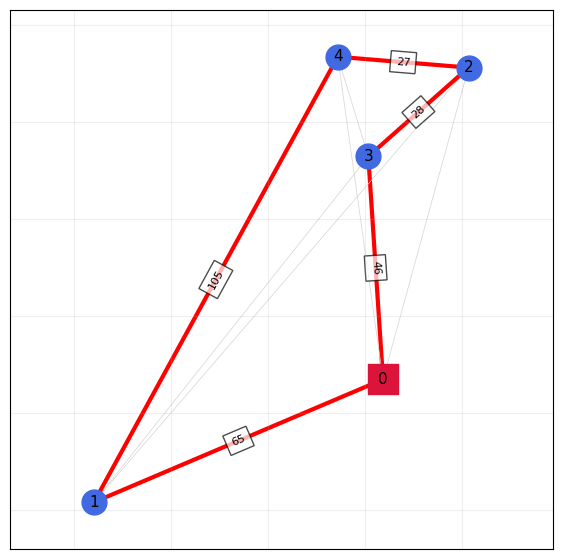

In [14]:
def visualize_route(opt_x, info):
	"""
	Visualiza a rota encontrada no grafo
	"""
	# Converter para dicionário de arcos
	x_dict = {}
	for (i, j), idx in info['x_index'].items():
		if opt_x[idx] == 1:
			x_dict[(i, j)] = 1
	
	custo_real = sum(info['c_core'][i, j] for (i, j) in x_dict)
	print(f"Total cost: {custo_real}")

	# mapa de sucessores
	next_node = {i: j for (i, j) in x_dict}

	routes = []

	# veículos começam em arestas (0,j)
	starts = [j for (i, j) in x_dict if i == 0]

	for start in starts:
		route = [0, start]
		current = start

		while True:
			current = next_node[current]
			route.append(current)

			if current == 0:
				break

		routes.append(route)

	# imprimir
	for k, r in enumerate(routes):
		print(f"Vehicle {k+1}: {' → '.join(map(str, r))}")
	
	# Visualizar no grafo
	coords = info['coords']
	c_core = info['c_core']
	n_nodes = len(coords)
	
	G = nx.Graph()
	for i in range(n_nodes):
		G.add_node(i, pos=(coords[i, 0], coords[i, 1]))
	
	# Todas as arestas possíveis (em cinza claro)
	for i in range(n_nodes):
		for j in range(i + 1, n_nodes):
			G.add_edge(i, j, weight=int(c_core[i, j]), color='lightgray', width=0.5)
	
	# Destacar arestas da solução
	for (i, j) in x_dict:
		# Se a aresta já existe, atualiza cor e largura
		if G.has_edge(i, j):
			G[i][j]['color'] = 'red'
			G[i][j]['width'] = 3
		else:
			G.add_edge(i, j, weight=int(c_core[i, j]), color='red', width=3)
	
	pos = {i: (coords[i, 0], coords[i, 1]) for i in range(n_nodes)}
	plt.figure(figsize=(7, 7))
	
	# Desenhar todas as arestas
	edges = G.edges()
	colors = [G[u][v]['color'] for u, v in edges]
	widths = [G[u][v]['width'] for u, v in edges]
	
	nx.draw_networkx_nodes(G, pos, nodelist=[0],
						  node_color="crimson", node_shape="s", node_size=450)
	nx.draw_networkx_nodes(G, pos,
						  nodelist=list(range(1, n_nodes)),
						  node_color="royalblue", node_shape="o", node_size=320)
	
	nx.draw_networkx_edges(G, pos, edge_color=colors, width=widths)
	nx.draw_networkx_labels(G, pos, font_size=11, font_color="black")
	
	# Mostrar pesos das arestas da solução
	edge_labels = {(u, v): G[u][v]['weight'] for (u, v) in x_dict.keys() if G.has_edge(u, v)}
	nx.draw_networkx_edge_labels(G, pos, edge_labels=edge_labels, font_size=8,
								 bbox=dict(facecolor='white', alpha=0.7))
	
	plt.axis("equal")
	plt.grid(True, alpha=0.2)
	plt.show()

# Visualizar a primeira solução ótima
visualize_route(opt_x_list[1], info)

## Check Solution

In [ ]:
def check_solution(x, Q, maxcut=True):
    x = np.array(x)
    if maxcut:
        if x[-1] == 1: 
            x = 1 - x[:-1]
        else: 
            x = x[:-1]
    return x @ Q @ x

check_solution(np.array([0, 1, 1, 1, 1, 1, 1, 1, 0, 1, 1, 1, 0, 1, 1, 1, 0, 1, 1, 1, 0, 1, 1, 1]), -Qmat)

# 7) QUBO to Max-Cut Reduction

We convert a QUBO problem

$$
\max_{x \in \{0,1\}^n} x^T Q x
$$

into an equivalent **Max-Cut** problem on a graph with **$n+1$ vertices**. This transformation follows the construction proposed by Bhattacharyya *et al.* (2025), where an auxiliary vertex is introduced to eliminate the linear terms that appear when mapping binary variables $\{0,1\}$ into Ising spins $\{-1,1\}$.

The adjacency matrix $A$ of the Max-Cut graph is constructed from the QUBO matrix $Q$ as

$$
A_{i,j} = -Q_{i,j}, \quad
A_{n,i} = \sum_{j=0}^{n-1} Q_{i,j}, \quad
A_{n,n} = 0.
$$

Solving the Max-Cut problem on this graph is energetically equivalent to solving the original QUBO. The extra vertex (the last one) is an auxiliary node introduced by the reduction and plays a special role in warm-start QAOA methods.


In [27]:
def normalize_qubo(Q):
    Q = np.array(Q, dtype=float)
    max_abs = np.max(np.abs(Q))
    if max_abs > 0:
        Q = Q / max_abs
    return Q

def qubo_to_maxcut_matrix(Q):
    """
    Convert QUBO matrix Q (n x n) to Max-Cut adjacency matrix A (n+1 x n+1)
    following the paper mapping.
    """
    n = Q.shape[0]
    A = np.zeros((n+1, n+1))

    # Edges between original variables
    for i in range(n):
        for j in range(i+1, n):
            A[i, j] = A[j, i] = -Q[i, j]

    # Edges to auxiliary node
    row_sums = Q.sum(axis=1)
    for i in range(n):
        A[i, n] = A[n, i] = row_sums[i]

    np.fill_diagonal(A, 0)
    return A

# Step 1: normalize QUBO
Q_sym = (Qmat + Qmat.T) / 2.0
Qmax = -Q_sym
Q_norm = normalize_qubo(Qmax)

# Step 2: build MaxCut matrix
A = qubo_to_maxcut_matrix(Q_norm)

print("Matrix A shape:", A.shape)

Matrix A shape: (21, 21)


This cell converts the adjacency matrix we created earlier to JSON format.

In [28]:
import json, os

def adjacency_matrix_to_json(A, filename="graph.json"):
    """
    Converts a weighted adjacency matrix to JSON-compatible format.

    Parameters:
    -----------
    A : list of list or np.ndarray
        n x n adjacency matrix, where A[i][j] is the weight of edge (i, j).
        If A[i][j] = 0, no edge is created (unless zero weights are valid).
        Matrix is assumed symmetric for undirected graphs.
    filename : str
        Output file name.
    """
    n = len(A)
    
    # Create list of nodes
    nodes = [{"id": i} for i in range(n)]
    
    # Create list of edges (links)
    links = []
    for i in range(n):
        # For undirected graphs, only traverse j > i to avoid duplication
        for j in range(i + 1, n):
            weight = A[i][j]
            # If you want to include edges with weight 0, remove the condition below
            if weight != 0:
                links.append({
                    "weight": float(weight),
                    "source": i,
                    "target": j
                })
    
    # Build final dictionary
    graph_data = {
        "directed": False,
        "multigraph": False,
        "graph": {},
        "nodes": nodes,
        "links": links
    }
    
    os.makedirs(os.path.dirname(filename), exist_ok=True)
    
    # Save to JSON file
    with open(filename, 'w', encoding='utf-8') as f:
        json.dump(graph_data, f, indent=2, ensure_ascii=False)
    
    print(f"File saved as {filename}")
    return graph_data
    
# Convert and save
n_qubits = info["n_vars"]+1
result = adjacency_matrix_to_json(A, f"../qamoo/data/problems/{n_qubits}q/problem_set_{n_qubits}q_10s_3o_0/problem_graph_2.json")

File saved as ../qamoo/data/problems/21q/problem_set_21q_10s_3o_0/problem_graph_2.json
